In [ ]:
# from google.colab import drive
# drive.mount('/content/drive/')
# %cd  '/content/drive/MyDrive/Primavera 2026/Deep Learning/'
# !ls
#################################### CONECTAR BASE DE DATOS A DRIVE #################################

In [ ]:
# !unzip archive.zip

In [1]:
import os
from typing import Any

import cv2
import json
import glob
import torch
import torchvision
import numpy as np
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import matplotlib.pyplot as plt
import torchvision.transforms as transforms

from tqdm import tqdm
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score
from torch.utils.data import DataLoader, Dataset


class TrackingEllipseGenerator(Dataset):
    def __init__(self, n_frames, n_tracks, image_shape=[200, 200],
                 duration_samples=[20, 100]):
        self.colors_track = np.random.uniform(0, 255, [n_tracks, 3])

        self.n_tracks = n_tracks
        self.n_frames = n_frames
        self.image_shape = image_shape

        self.frame_ids, self.ids_data, self.tracks_data = self.define_coordinates_tracks(duration=duration_samples,
                                                                                         speed_limit=image_shape[
                                                                                                         0] // 10)

        self.cats = np.zeros([n_tracks],dtype=np.int32)
        self.indices_track = []
        self.frame_names = []
        indices = np.arange(len(self.tracks_data))

        for j in range(n_frames):
            valid_indx = self.frame_ids == j
            self.indices_track += [indices[valid_indx]]
            self.frame_names += ['frame{:d}'.format(j)]

    def define_coordinates_tracks(self, duration=[5, 10], speed_limit=20):
        speeds = np.tile(np.random.randint(-speed_limit, speed_limit, [self.n_tracks, 2]), 2)

        coordinates_start = np.empty([self.n_tracks, 4], dtype=np.int32)
        delta0 = int(self.image_shape[1] * 0.1)
        delta1 = int(self.image_shape[0] * 0.1)
        coordinates_start[:, :2] = np.random.randint([delta1, delta0],
                                                     [self.image_shape[1] - delta0, self.image_shape[0] - delta1],
                                                     [self.n_tracks, 2])

        upper_width = max(delta0, 30)
        upper_height = max(delta1, 30)

        coordinates_start[:, 2:] = coordinates_start[:, :2] + np.random.randint([10, 10], [upper_width, upper_height],
                                                                                [self.n_tracks, 2], dtype=np.int32)
        coordinates_start[:, 0:4:2] = np.clip(coordinates_start[:, 0:4:2], 0, self.image_shape[0])
        coordinates_start[:, 1:4:2] = np.clip(coordinates_start[:, 1:4:2], 0, self.image_shape[1])
        # total_annotations = []

        time_spam = np.random.randint(duration[0], min(self.n_frames, duration[1]), [self.n_tracks])
        start_track = np.random.randint(0, self.n_frames - time_spam, [self.n_tracks])
        end_track = start_track + time_spam

        tracks = []
        ids = []
        frames = []
        for j in range(self.n_tracks):
            for i in range(self.n_frames):
                if i >= start_track[j]:
                    # track = coordinates_start[j]
                    # tracks += [track]
                    if i <= end_track[j]:

                        coordinates_start[j] += speeds[j]

                        if coordinates_start[j, 0::2].max() > self.image_shape[1] or coordinates_start[j,
                                                                                     0::2].min() < 0:  # Slowdown exponentially
                            coordinates_start[j, 0::2] -= speeds[j, 0::2]
                            speeds[j, 0::2] = -speeds[j, 0::2] // 2

                        if coordinates_start[j, 1::2].max() > self.image_shape[0] or coordinates_start[j,
                                                                                     1::2].min() < 0:
                            coordinates_start[j, 1::2] -= speeds[j, 1::2]
                            speeds[j, 1::2] = -speeds[j, 1::2] // 2

                        tracks += [coordinates_start[j].copy()]
                        ids += [j]
                        frames += [i]

        final_tracks = np.array(tracks)
        frames = np.array(frames, dtype=np.int32)
        ids = np.array(ids, dtype=np.int32)
        # label = {"boxes": ids,"labels":final_tracks}
        return frames, ids,final_tracks


    def get_frame(self, idx):
        tracks = self.tracks_data[self.indices_track[idx]]
        img = self.build_image_tracks(tracks, self.ids_data[self.indices_track[idx]])
        return tracks, img


    def build_image_tracks(self, tracks, ids_tracks):
        img = np.zeros(self.image_shape + [3], dtype=np.uint8)
        for i, track in enumerate(tracks):
            img = create_images_circles(track, img, self.colors_track[ids_tracks[i]])
        return img

    def __getitem__(self, idx):
        target  = {}
        bboxes,img = self.get_frame(idx)
        target['boxes'] = bboxes
        target['labels'] = self.cats[self.ids_data[self.indices_track[idx]]]
        return img , target

    def __len__(self):
        return self.n_frames

def draw_boxes(img, bboxes, color_track= (0, 255, 0),thickness=2):

    for i in range(len(bboxes)):
        point1 = bboxes[i, :2].astype(np.int32)
        point2 = bboxes[i, 2:4].astype(np.int32)
        img = cv2.rectangle(img, point1, point2, color=color_track, thickness=thickness)
    return img

def create_images_circles(coordinates, image, color, thickness=3):
    center_point = (coordinates[:2] + coordinates[2:]) // 2
    radius = (coordinates[2:] - coordinates[:2]) // 2
    axesLength = (radius[0], radius[1])
    angle = 0
    start_angle = 0
    end_angle = 360
    image = cv2.ellipse(image, center=center_point, axes=axesLength, angle=angle,
                        startAngle=start_angle, endAngle=end_angle, color=color, thickness=thickness)
    return image


def create_images_rectangle(coordinates, image, color, thickness=3):
    # h,w = image_shape[0],image_shape[1]
    point1 = coordinates[:2].astype(np.int32)
    point2 = coordinates[2:4].astype(np.int32)
    image = cv2.rectangle(image, point1, point2, color=color, thickness=thickness)
    return image




# Explorar dataset
1. Analice los datos que salen del dataset y comente de que se tratan

In [46]:
dataset = TrackingEllipseGenerator(n_frames=100,n_tracks=5)

[[ 28 161  51 190]
 [ 96  36 109  56]
 [ 84 161 108 178]
 [ 88  17 106  41]
 [170  58 189  74]]
[0 0 0 0 0]


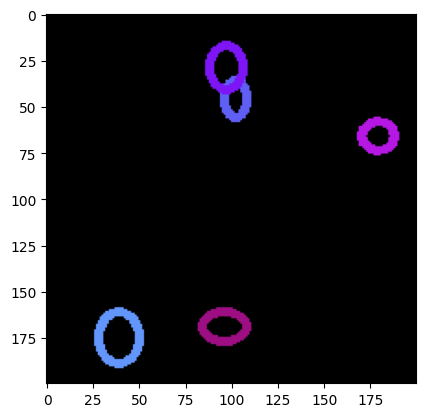

In [82]:
# index = 0
index += 1
img,target = dataset[index]

plt.imshow(img)
print(target['boxes'])
print(target['labels'])

In [77]:
# img = draw_boxes(img,target['boxes'])
# plt.imshow(img)

# Entrenamiento
1. Realice un entrenamiento con una red One-stage
2. Grafique las metricas obtenidas
3. ¿Los resultados fueron buenos o malos? ¿Por qué crees que sucedió?

In [45]:
def detection_collate(batch):
    # Frames have a variable number of boxes, so targets are kept as a list
    images = torch.stack([torch.from_numpy(img).permute(2, 0, 1).float() / 255. for img, _ in batch])
    targets = []
    for _, target in batch:
        targets += [{'boxes': torch.as_tensor(target['boxes'], dtype=torch.float32).reshape(-1, 4),
                     'labels': torch.as_tensor(target['labels'], dtype=torch.int64).reshape(-1)}]
    return images, targets


def conv_block(in_channels, out_channels):
    return nn.Sequential(nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
                         nn.BatchNorm2d(out_channels),
                         nn.ReLU(inplace=True))


class OneStageModel(nn.Module):
    """
    YOLO-like one-stage detector. The image is divided in a grid of cells (one cell per `stride` pixels);
    for every cell the model predicts:
      - n_cats + 1 class logits (index 0 is background),
      - 4 box values (tx, ty, tw, th): center offset inside the cell (after sigmoid) and log(width/stride),
        log(height/stride).
    """

    def __init__(self, n_cats=1, stride=8):
        super().__init__()
        self.n_cats = n_cats
        self.n_classes = n_cats + 1
        self.stride = stride

        self.backbone = nn.Sequential(conv_block(3, 32), conv_block(32, 32), nn.MaxPool2d(2),      # /2
                                      conv_block(32, 64), conv_block(64, 64), nn.MaxPool2d(2),     # /4
                                      conv_block(64, 128), conv_block(128, 128), nn.MaxPool2d(2),  # /8
                                      conv_block(128, 128), conv_block(128, 128))
        self.cls_head = nn.Sequential(conv_block(128, 128), nn.Conv2d(128, self.n_classes, kernel_size=1))
        self.box_head = nn.Sequential(conv_block(128, 128), nn.Conv2d(128, 4, kernel_size=1))

    def forward(self, x):
        features = self.backbone(x)
        return self.cls_head(features), self.box_head(features)  # [B, C+1, S, S], [B, 4, S, S]

    def encode_targets(self, targets, grid_shape):
        # Assign each box to the cell that contains its center
        gh, gw = grid_shape
        device = targets[0]['boxes'].device
        cls_target = torch.zeros([len(targets), gh, gw], dtype=torch.int64, device=device)
        box_target = torch.zeros([len(targets), 4, gh, gw], dtype=torch.float32, device=device)
        for b, target in enumerate(targets):
            boxes = target['boxes']
            if len(boxes) == 0:
                continue
            cx = (boxes[:, 0] + boxes[:, 2]) / 2 / self.stride
            cy = (boxes[:, 1] + boxes[:, 3]) / 2 / self.stride
            w = (boxes[:, 2] - boxes[:, 0]).clamp(min=1) / self.stride
            h = (boxes[:, 3] - boxes[:, 1]).clamp(min=1) / self.stride
            j = cx.long().clamp(0, gw - 1)
            i = cy.long().clamp(0, gh - 1)
            cls_target[b, i, j] = target['labels'] + 1
            box_target[b, :, i, j] = torch.stack([cx - j, cy - i, w.log(), h.log()])
        return cls_target, box_target

    def decode(self, box_pred):
        # [B, 4, S, S] -> [B, S*S, 4] boxes in (x1, y1, x2, y2) pixel coordinates
        _, _, gh, gw = box_pred.shape
        ii, jj = torch.meshgrid(torch.arange(gh, device=box_pred.device),
                                torch.arange(gw, device=box_pred.device), indexing='ij')
        cx = (jj + box_pred[:, 0].sigmoid()) * self.stride
        cy = (ii + box_pred[:, 1].sigmoid()) * self.stride
        w = box_pred[:, 2].clamp(max=10).exp() * self.stride
        h = box_pred[:, 3].clamp(max=10).exp() * self.stride
        boxes = torch.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], dim=-1)
        return boxes.flatten(1, 2)

    @torch.no_grad()
    def predict(self, cls_logits, box_pred, score_threshold=0.05, iou_threshold=0.5):
        probs = cls_logits.softmax(dim=1)[:, 1:].flatten(2).transpose(1, 2)  # [B, S*S, n_cats]
        scores, labels = probs.max(dim=-1)
        boxes = self.decode(box_pred)
        detections = []
        for b in range(len(boxes)):
            keep = scores[b] > score_threshold
            b_boxes, b_scores, b_labels = boxes[b][keep], scores[b][keep], labels[b][keep]
            keep = torchvision.ops.batched_nms(b_boxes, b_scores, b_labels, iou_threshold)
            detections += [{'boxes': b_boxes[keep], 'scores': b_scores[keep], 'labels': b_labels[keep]}]
        return detections


class DetectionLoss(nn.Module):
    """Cross entropy over grid cells (background + classes) plus smooth L1 on the boxes of positive cells."""

    def __init__(self, bg_weight=0.1, box_weight=1.0):
        super().__init__()
        self.bg_weight = bg_weight
        self.box_weight = box_weight

    def forward(self, cls_logits, box_pred, cls_target, box_target):
        weight = torch.ones(cls_logits.shape[1], device=cls_logits.device)
        weight[0] = self.bg_weight
        ce_loss = F.cross_entropy(cls_logits, cls_target, weight=weight)

        positive = cls_target > 0
        if positive.any():
            pred = torch.cat([box_pred[:, :2].sigmoid(), box_pred[:, 2:]], dim=1)
            pred = pred.permute(0, 2, 3, 1)[positive]
            target = box_target.permute(0, 2, 3, 1)[positive]
            box_loss = F.smooth_l1_loss(pred, target)
        else:
            box_loss = box_pred.sum() * 0.
        return ce_loss + self.box_weight * box_loss, ce_loss, box_loss


def average_precision(detections, targets, n_cats, iou_threshold=0.5):
    """Mean over categories of the VOC (all-point interpolated) average precision."""
    aps = []
    for c in range(n_cats):
        scores, matches = [], []
        n_gt = 0
        for det, target in zip(detections, targets):
            gt_boxes = target['boxes'][target['labels'] == c]
            n_gt += len(gt_boxes)
            mask = det['labels'] == c
            d_boxes, d_scores = det['boxes'][mask], det['scores'][mask]
            order = d_scores.argsort(descending=True)
            d_boxes, d_scores = d_boxes[order], d_scores[order]
            used = torch.zeros(len(gt_boxes), dtype=torch.bool)
            ious = torchvision.ops.box_iou(d_boxes, gt_boxes) if len(gt_boxes) > 0 else None
            for k in range(len(d_boxes)):
                is_tp = False
                if ious is not None:
                    iou = ious[k].clone()
                    iou[used] = -1
                    best = iou.argmax()
                    if iou[best] >= iou_threshold:
                        used[best] = True
                        is_tp = True
                scores += [d_scores[k].item()]
                matches += [is_tp]
        if n_gt == 0:
            continue
        if len(scores) == 0:
            aps += [0.]
            continue
        order = np.argsort(-np.array(scores))
        tp = np.array(matches, dtype=np.float64)[order]
        tp_cum = np.cumsum(tp)
        fp_cum = np.cumsum(1 - tp)
        recall = tp_cum / n_gt
        precision = tp_cum / np.maximum(tp_cum + fp_cum, 1e-12)
        recall = np.concatenate([[0.], recall, [1.]])
        precision = np.concatenate([[0.], precision, [0.]])
        precision = np.maximum.accumulate(precision[::-1])[::-1]
        idx = np.where(recall[1:] != recall[:-1])[0]
        aps += [np.sum((recall[idx + 1] - recall[idx]) * precision[idx + 1])]
    return float(np.mean(aps)) if len(aps) > 0 else 0.


def run_epoch(model, loader, loss_fn, optimizer=None, device='cpu'):
    """
    Runs one pass over the loader (training if an optimizer is given).
    Accuracy is the per-cell classification accuracy on the cells that contain an object
    (on all cells it is dominated by background and always close to 1).
    """
    training = optimizer is not None
    model.train(training)
    total_loss, total_ce, n_batches = 0., 0., 0
    correct, n_positive = 0, 0
    all_detections, all_targets = [], []

    with torch.set_grad_enabled(training):
        for images, targets in loader:
            images = images.to(device)
            targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

            cls_logits, box_pred = model(images)
            cls_target, box_target = model.encode_targets(targets, cls_logits.shape[2:])
            loss, ce_loss, _ = loss_fn(cls_logits, box_pred, cls_target, box_target)

            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item()
            total_ce += ce_loss.item()
            n_batches += 1
            positive = cls_target > 0
            correct += (cls_logits.argmax(dim=1)[positive] == cls_target[positive]).sum().item()
            n_positive += positive.sum().item()

            detections = model.predict(cls_logits.detach(), box_pred.detach())
            all_detections += [{k: v.cpu() for k, v in d.items()} for d in detections]
            all_targets += [{k: v.cpu() for k, v in t.items()} for t in targets]

    return {'loss': total_loss / max(n_batches, 1),
            'cross_entropy': total_ce / max(n_batches, 1),
            'accuracy': correct / max(n_positive, 1),
            'AP50': average_precision(all_detections, all_targets, model.n_cats, iou_threshold=0.5)}


def train(model, loader, optimizer, loss_fn, device='cpu'):
    return run_epoch(model, loader, loss_fn, optimizer=optimizer, device=device)


def evaluate(model, loader, loss_fn, device='cpu'):
    return run_epoch(model, loader, loss_fn, optimizer=None, device=device)



In [83]:
train_dataset = TrackingEllipseGenerator(n_frames=300,n_tracks=6,)
val_dataset = TrackingEllipseGenerator(n_frames=100,n_tracks=3)

n_cats = 1
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, collate_fn=detection_collate)
val_loader = DataLoader(val_dataset, batch_size=16, collate_fn=detection_collate)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = OneStageModel(n_cats=n_cats).to(device)
loss_fn = DetectionLoss()
n_epochs = 10
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
train_metrics = []
val_metrics = []
for epoch in tqdm(range(n_epochs)):
    metrics_train = train(model, train_loader, optimizer, loss_fn, device)
    metrics_val = evaluate(model, val_loader, loss_fn, device)
    tqdm.write('epoch {:d} | train: {} | val: {}'.format(
        epoch, ', '.join('{}={:.4f}'.format(k, v) for k, v in metrics_train.items()),
        ', '.join('{}={:.4f}'.format(k, v) for k, v in metrics_val.items())))

    train_metrics += [metrics_train]
    val_metrics += [metrics_val]

 10%|████▍                                       | 1/10 [00:07<01:09,  7.73s/it]

epoch 0 | train: loss=0.6309, cross_entropy=0.3638, accuracy=0.7917, AP50=0.0284 | val: loss=0.3590, cross_entropy=0.1841, accuracy=0.0000, AP50=0.0000


 20%|████████▊                                   | 2/10 [00:13<00:53,  6.66s/it]

epoch 1 | train: loss=0.1638, cross_entropy=0.1274, accuracy=0.9389, AP50=0.4652 | val: loss=0.2288, cross_entropy=0.1083, accuracy=0.0000, AP50=0.0000


 30%|█████████████▏                              | 3/10 [00:19<00:45,  6.51s/it]

epoch 2 | train: loss=0.0720, cross_entropy=0.0556, accuracy=0.9694, AP50=0.8730 | val: loss=0.1174, cross_entropy=0.0693, accuracy=0.1497, AP50=0.3489


... (10 outputs left out)

 90%|███████████████████████████████████████▌    | 9/10 [00:48<00:04,  4.33s/it]

epoch 8 | train: loss=0.0144, cross_entropy=0.0071, accuracy=0.9972, AP50=0.9942 | val: loss=0.0513, cross_entropy=0.0119, accuracy=0.9465, AP50=0.6478


100%|███████████████████████████████████████████| 10/10 [00:51<00:00,  5.17s/it]

epoch 9 | train: loss=0.0096, cross_entropy=0.0054, accuracy=1.0000, AP50=1.0000 | val: loss=0.0590, cross_entropy=0.0410, accuracy=0.4385, AP50=0.8100


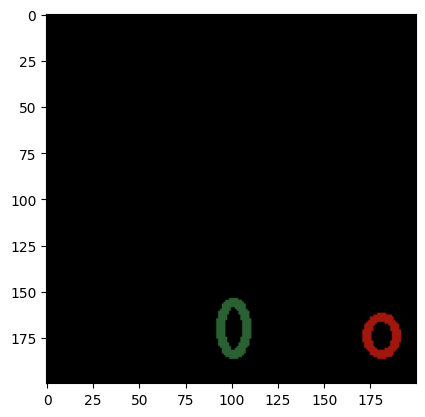

classification_shape:  torch.Size([16, 2, 25, 25])


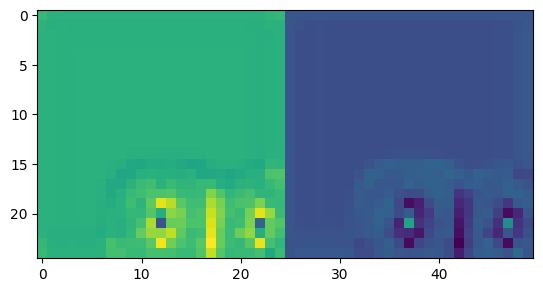

In [91]:
image_sample,target = next(iter(train_loader))
image_plot = image_sample[0].permute(1,2,0).cpu().numpy()
plt.imshow(image_plot)
plt.show()
class_target = 1
with torch.no_grad():

    classifications, locations = model(image_sample.to(device))
    print("classification_shape: ",classifications.size())
    # print(classifications[0])
    tensor_data = classifications[0].detach().cpu().numpy()
    tensor_data = np.concatenate([tensor_data[0],tensor_data[1]],axis=1)
    plt.imshow(tensor_data)
    plt.show()
    # plt.imshow(tensor_data[1])
    ###### CODE HERE ######



# Entrenamiento de base de datos de células
1. Grafique los bounding boxes obtenidos en la base de datos.
2. Repita el proceso con los datos obtenidos.
3. Grafique las métricas obtenidas para el problema de detección de elipses y detección de células.
4. ¿Los resultados fueron buenos o malos? ¿Por qué crees que sucedió?.

In [93]:

class DatasetCells(Dataset):
    def __init__(self, base_path:str,):
        self.samples, self.images_info = [], []

        js = glob.glob(os.path.join(base_path, "**/*.json"), recursive=True)
        if js:
            with open(js[0], 'r') as f: data = json.load(f)
            self.images_info = data['images']
            img_f = glob.glob(os.path.join(base_path, "**/" + self.images_info[0]['file_name']), recursive=True)
            self.img_dir = os.path.dirname(img_f[0]) if img_f else os.path.dirname(js[0])
        else:
            raise ValueError("No JSON file found in the base path")

        self.annotations = self.generate_annotations(data['annotations'])

    def generate_annotations(self, annotations):
        annotations_per_image = {}
        for info in self.images_info:
            ann_image = []
            for ann in annotations:
                if ann['image_id'] == info['id']:
                    ann_image += [ann]
            annotations_per_image[info['id']] = ann_image
        return annotations_per_image

    def __len__(self):
        return len(self.images_info)

    def __getitem__(self, idx):
        try:
            info = self.images_info[idx]
            img = cv2.imread(os.path.join(self.img_dir, info['file_name']))
            anns = self.annotations.get(info['id'], [])
            if len(anns) > 0:
                boxes = [[a['bbox'][0], a['bbox'][1], a['bbox'][0] + a['bbox'][2], a['bbox'][1] + a['bbox'][3]] for a in anns]
                boxes = np.array(boxes, dtype=np.float32)
                classes = np.array([a['category_id'] for a in anns], dtype=np.int64)
            else:
                boxes = np.empty((0, 4), dtype=np.float32)
                classes = np.empty((0,), dtype=np.int64)
            target = {}

            target['boxes'] = boxes
            target['labels'] = classes - 1
            return img, target

        except:
            return np.zeros((512, 512, 3), dtype=np.uint8), {'boxes': np.empty((0, 4), dtype=np.float32), 'labels': np.empty((0,), dtype=np.int64)}


In [94]:
train_dataset = DatasetCells('/home/luis/2026/CC6204-Deep-Learning3/data/archive_bbcd/train')
val_dataset = DatasetCells('/home/luis/2026/CC6204-Deep-Learning3/data/archive_bbcd/valid')
###### CODE HERE ######


[[ 81.  18. 194. 115.]
 [ 43. 259. 144. 351.]
 [347. 355. 448. 447.]
 [ 97. 362. 198. 454.]
 [195. 167. 297. 277.]
 [399. 232. 501. 342.]
 [536. 274. 638. 384.]
 [559. 136. 640. 245.]
 [ 66. 136. 153. 241.]
 [266. 181. 368. 291.]
 [254. 268. 356. 378.]
 [225. 358. 328. 457.]
 [285.  30. 509. 238.]
 [477. 411. 523. 440.]]
[1 1 1 1 1 1 1 1 1 1 1 1 2 0]


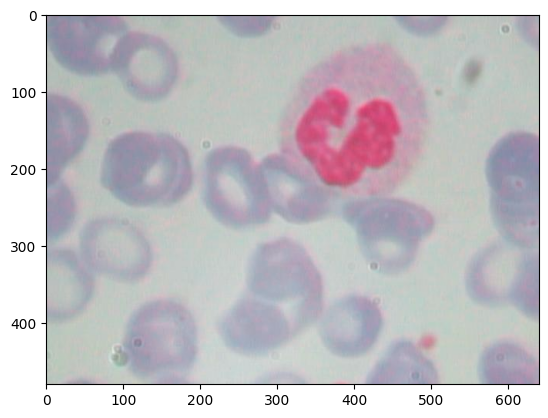

In [96]:
# index = 0
index += 1
img,target = train_dataset[index]

print(target['boxes'])
print(target['labels'])
plt.imshow(img)


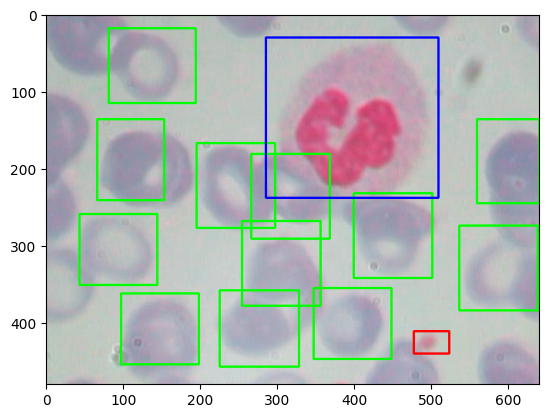

In [99]:
def draw_boxes_categories(img, bboxes, cats, color_track,thickness=2):

    for i in range(len(bboxes)):
        point1 = bboxes[i, :2].astype(np.int32)
        point2 = bboxes[i, 2:4].astype(np.int32)
        cat = int(cats[i])
        img = cv2.rectangle(img, point1, point2, color=color_track[cat].tolist(), thickness=thickness)
    return img

color_track = np.array([[255,0,0],[0,255,0],[0,0,255]])
img = draw_boxes_categories(img,target['boxes'],target['labels'],color_track)
plt.imshow(img)

In [108]:

n_classes = 3
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, collate_fn=detection_collate)
val_loader = DataLoader(val_dataset, batch_size=16, collate_fn=detection_collate)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = OneStageModel(n_cats=n_classes).to(device)
loss_fn = DetectionLoss()
n_epochs = 10
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
train_metrics = []
val_metrics = []
for epoch in tqdm(range(n_epochs)):
    metrics_train = train(model, train_loader, optimizer, loss_fn, device)
    metrics_val = evaluate(model, val_loader, loss_fn, device)
    tqdm.write('epoch {:d} | train: {} | val: {}'.format(
        epoch, ', '.join('{}={:.4f}'.format(k, v) for k, v in metrics_train.items()),
        ', '.join('{}={:.4f}'.format(k, v) for k, v in metrics_val.items())))
    train_metrics += [metrics_train]
    val_metrics += [metrics_val]



 10%|████▍                                       | 1/10 [00:11<01:43, 11.46s/it]

epoch 0 | train: loss=0.1626, cross_entropy=0.0991, accuracy=0.0539, AP50=0.2166 | val: loss=0.1739, cross_entropy=0.1354, accuracy=0.0000, AP50=0.0747


 20%|████████▊                                   | 2/10 [00:21<01:26, 10.80s/it]

epoch 1 | train: loss=0.1080, cross_entropy=0.0780, accuracy=0.1937, AP50=0.4152 | val: loss=0.1086, cross_entropy=0.0766, accuracy=0.1119, AP50=0.4043


 30%|█████████████▏                              | 3/10 [00:33<01:17, 11.13s/it]

epoch 2 | train: loss=0.0996, cross_entropy=0.0720, accuracy=0.2398, AP50=0.5517 | val: loss=0.1163, cross_entropy=0.0890, accuracy=0.2767, AP50=0.4827


... (10 outputs left out)

 90%|███████████████████████████████████████▌    | 9/10 [01:39<00:10, 10.77s/it]

epoch 8 | train: loss=0.0840, cross_entropy=0.0605, accuracy=0.3320, AP50=0.7700 | val: loss=0.0845, cross_entropy=0.0602, accuracy=0.3420, AP50=0.7821


100%|███████████████████████████████████████████| 10/10 [01:49<00:00, 10.96s/it]

epoch 9 | train: loss=0.0820, cross_entropy=0.0590, accuracy=0.3473, AP50=0.7986 | val: loss=0.0840, cross_entropy=0.0605, accuracy=0.3244, AP50=0.8217


Text(0.5, 0, 'cross_entropy')

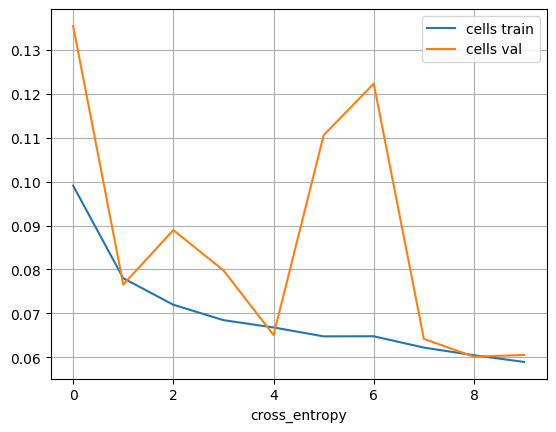

In [109]:
import pandas as pd
data_cells_train = pd.DataFrame(train_metrics)
data_cells_val = pd.DataFrame(val_metrics)
epochs_cells = np.arange(len(data_cells_val))
column = 'cross_entropy'
plt.plot(epochs_cells,data_cells_train[column],label='cells train')
plt.plot(epochs_cells,data_cells_val[column],label='cells val')
plt.grid()
plt.legend()
plt.xlabel('epoch')
plt.xlabel(column)

Text(0.5, 0, 'accuracy')

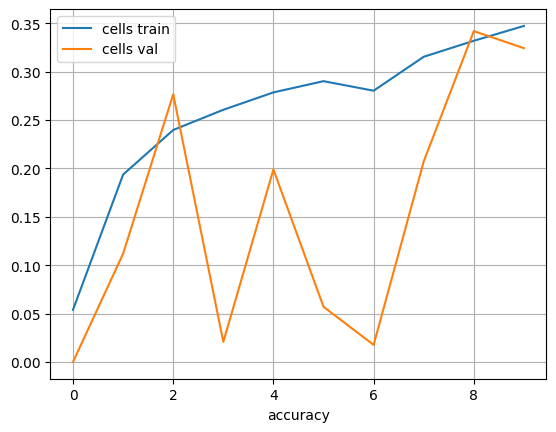

In [110]:
column = 'accuracy'
plt.plot(epochs_cells,data_cells_train[column],label='cells train')
plt.plot(epochs_cells,data_cells_val[column],label='cells val')
plt.grid()
plt.legend()
plt.xlabel('epoch')
plt.xlabel(column)

Text(0.5, 0, 'AP50')

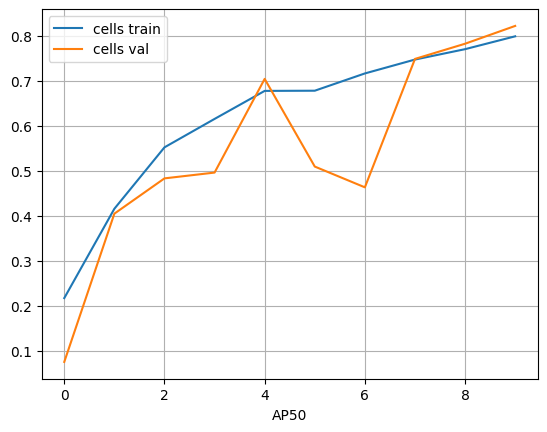

In [111]:
column = 'AP50'
plt.plot(epochs_cells,data_cells_train[column],label='cells train')
plt.plot(epochs_cells,data_cells_val[column],label='cells val')
plt.grid()
plt.legend()
plt.xlabel('epoch')
plt.xlabel(column)

# Mapa de categorias
1. Grafique las probabilidades de cada clase para una imagen de entrenamiento.

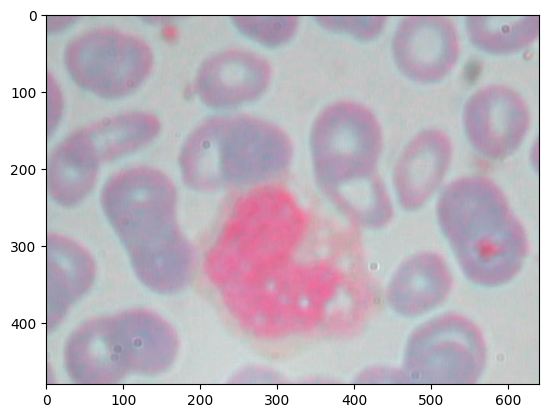

classification_shape:  torch.Size([16, 4, 60, 80])


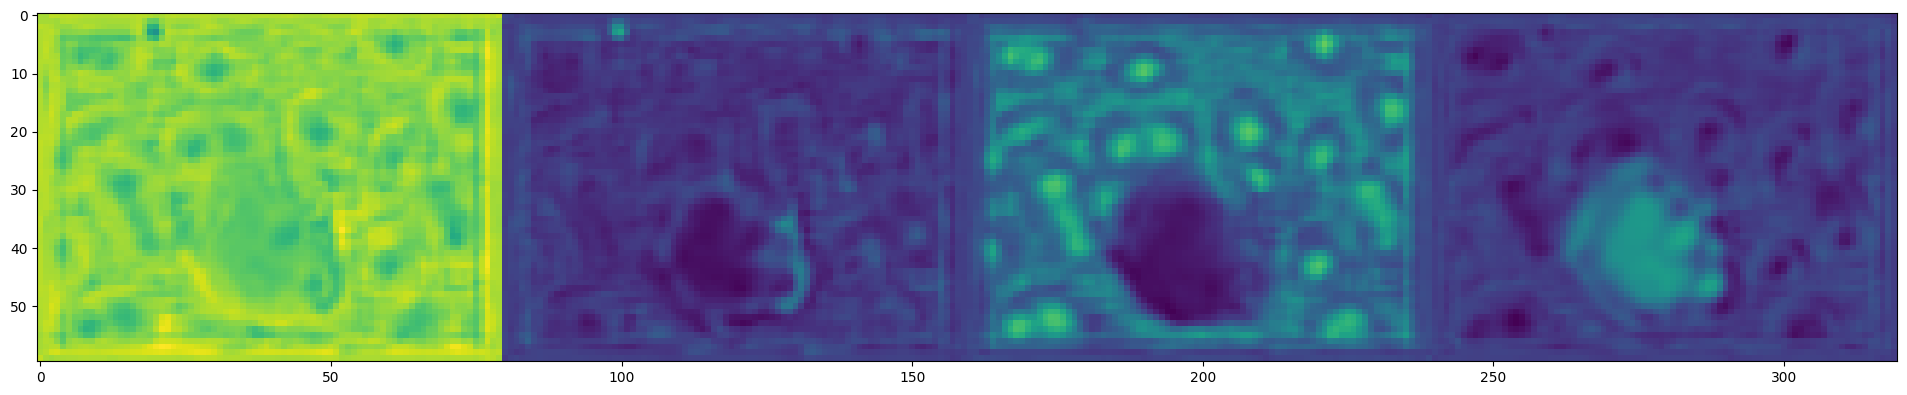

In [124]:
image_sample,target = next(iter(train_loader))
image_plot = image_sample[0].permute(1,2,0).cpu().numpy()
plt.imshow(image_plot)
plt.show()
class_target = 1
with torch.no_grad():

    classifications, locations = model(image_sample.to(device))
    print("classification_shape: ",classifications.size())
    tensor_data = classifications[0].detach().cpu().numpy()
    tensor_data = np.concatenate([tensor_data[0],tensor_data[1],tensor_data[2],tensor_data[3]],axis=1)
    # tensor_data = np.concatenate([tensor_data[0],tensor_data[1],tensor_data[2]],axis=1)
    # tensor_data = np.concatenate([tensor_data[0],tensor_data[1]],axis=1)
    plt.figure(figsize=(24,6))
    plt.imshow(tensor_data)
    plt.show()
    ###### CODE HERE ######

